MongoDB Analytics Pipeline Project

---


DSCI 531 – Big Data Management

---


Jesse Greyshock

In [2]:
!pip install "pymongo[srv]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 23.3 MB/s eta 0:00:00


In [3]:
import os
from pymongo.mongo_client import MongoClient
from pymongo.server_api import ServerApi

# The connection string comes from an environment variable so credentials never live in the notebook.
# Example: export MONGODB_URI="mongodb+srv://<user>:<password>@<cluster>.mongodb.net/?appName=Cluster0"
# (In Google Colab, store it as a secret and read it with google.colab.userdata.get instead.)
uri = os.environ["MONGODB_URI"]

# Create a new client and connect to the server
client = MongoClient(uri, server_api=ServerApi('1'))

# Send a ping to confirm a successful connection
try:
    client.admin.command('ping')
    print("Pinged your deployment. You successfully connected to MongoDB!")
except Exception as e:
    print(e)

Pinged your deployment. You successfully connected to MongoDB!


In [4]:
db = client["Mongo_Project"]

# Part 1 – Operational Task
Simulating a movie ticket purchase using an atomic update.

In [5]:
requested_tickets = 3

result = db.showings.update_one(
    {
        "showing_id": "SH1001",
        "available_seats": {"$gte": requested_tickets} # non-negative amount of seats must be available
    },
    {
        "$inc": {
            "available_seats": -requested_tickets, # decreasing available seats
            "tickets_sold": requested_tickets # increasing tickets sold
        }
    }
)

if result.modified_count == 1:
    print("Purchase completed successfully.")
else:
    print("Not enough seats available.")

Purchase completed successfully.


# Part 2 – Create Reporting Collections
Creating aggregation pipelines to summarize ticket sales.

In [10]:
def refresh_reporting_tables():

    # Movie-level reporting pipeline
    db.ticket_sales.aggregate([
        {
            "$group": {
                "_id": "$title",
                "total_purchases": {"$sum": 1},
                "tickets_sold": {"$sum": "$tickets_bought"},
                "total_revenue": {
                    "$sum": {
                        "$multiply": ["$tickets_bought", "$ticket_price"]
                    }
                }
            }
        },
        {
            "$merge": "rpt_ticket_sales_by_movie"
        }
    ])


    # Genre-level reporting pipeline
    db.ticket_sales.aggregate([
        {
            "$group": {
                "_id": "$genre",
                "total_purchases": {"$sum": 1},
                "tickets_sold": {"$sum": "$tickets_bought"},
                "total_revenue": {
                    "$sum": {
                        "$multiply": ["$tickets_bought", "$ticket_price"]
                    }
                }
            }
        },
        {
            "$merge": "rpt_ticket_sales_by_genre"
        }
    ])

In [11]:
refresh_reporting_tables()

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

movie_cursor = db.rpt_ticket_sales_by_movie.find()
genre_cursor = db.rpt_ticket_sales_by_genre.find()

movie_df = pd.DataFrame(list(movie_cursor))
genre_df = pd.DataFrame(list(genre_cursor))

movie_df = movie_df.rename(columns={"_id": "title"})
genre_df = genre_df.rename(columns={"_id": "genre"})

print(movie_df.sort_values("tickets_sold", ascending=False).head(10))
print(genre_df.sort_values("tickets_sold", ascending=False).head(10))



                  title  tickets_sold  total_purchases  total_revenue
7            Galaxy Run        189860            69861      2419036.0
6     Starlight Station        172806            63664      2202715.0
8          Neon Horizon        129013            47216      1644482.0
10          Pixel Quest        111967            41038      1428314.5
1         Turbo Trouble        100341            36905      1279449.0
17       Paws and Claws         99477            36666      1268950.0
11      Rocket Roadtrip         98974            36355      1260217.0
13         Wonder Woods         89037            32705      1134406.0
18     The Last Lantern         88437            32606      1127572.0
19  Maple Street Summer         82597            30383      1053755.0
       genre  tickets_sold  total_purchases  total_revenue
1     Sci-Fi        362666           133525      4621751.0
6     Action        312291           114671      3981670.5
3     Comedy        260293            95760      3317

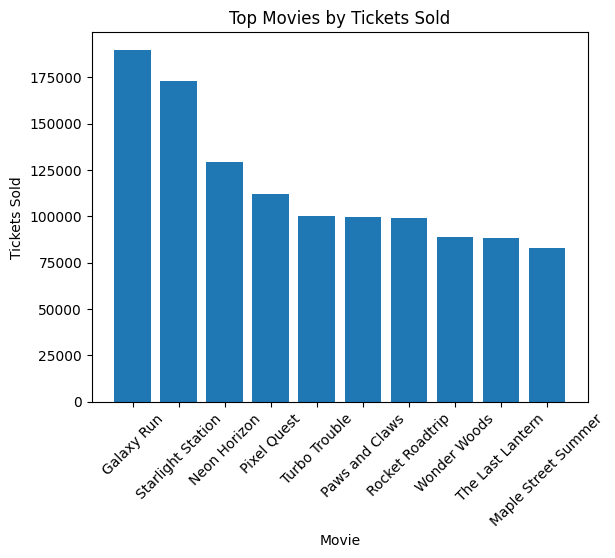

In [13]:
top_movies = movie_df.sort_values("tickets_sold", ascending=False).head(10)

plt.figure()
plt.bar(top_movies["title"], top_movies["tickets_sold"])
plt.xticks(rotation=45)
plt.title("Top Movies by Tickets Sold")
plt.xlabel("Movie")
plt.ylabel("Tickets Sold")
plt.show()

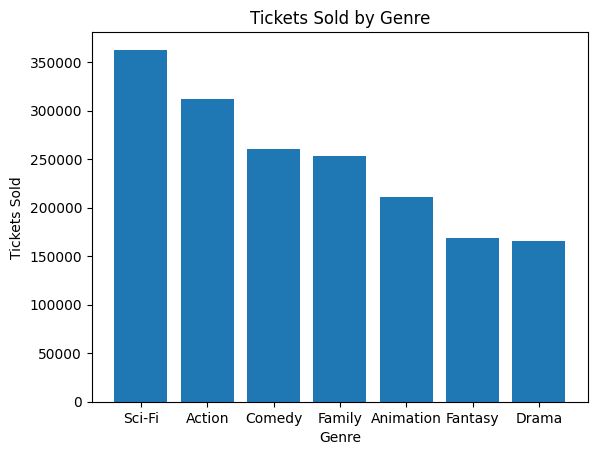

In [14]:
top_genres = genre_df.sort_values("tickets_sold", ascending=False)

plt.figure()
plt.bar(top_genres["genre"], top_genres["tickets_sold"])
plt.title("Tickets Sold by Genre")
plt.xlabel("Genre")
plt.ylabel("Tickets Sold")
plt.show()

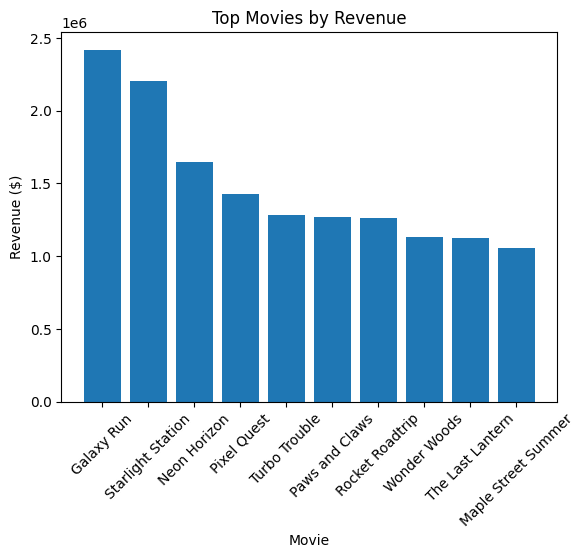

In [16]:
top_revenue = movie_df.sort_values("total_revenue", ascending=False).head(10)

plt.figure()
plt.bar(top_revenue["title"], top_revenue["total_revenue"])
plt.xticks(rotation=45)
plt.title("Top Movies by Revenue")
plt.xlabel("Movie")
plt.ylabel("Revenue ($)")
plt.show()

# Part 3 – Step 1: Archive an Older Movie
Moving MOV106 ticket sales to archive collection.

In [8]:
db.ticket_sales.aggregate([
    {
        "$match": {"movie_id": "MOV106"}
    },
    {
        "$merge": {
            "into": "ticket_sales_archive"
        }
    }
])

In [8]:
db.ticket_sales.delete_many({"movie_id": "MOV106"})

DeleteResult({'n': 12984, 'ok': 1.0}, acknowledged=True)